In [1]:
import numpy as np
import scipy

import matplotlib.pyplot as plt
import seaborn as sns

from tqdm import tqdm

import tifffile
import fastplotlib as fpl

To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Unable to find extension: VK_EXT_swapchain_colorspace


Available devices:
🯄 | AMD Radeon Graphics (RADV REMBRANDT) | IntegratedGPU | Vulkan | Mesa 22.3.6
✅ (default) | NVIDIA T1200 Laptop GPU | DiscreteGPU | Vulkan | 535.129.03
❗ | llvmpipe (LLVM 15.0.6, 256 bits) | CPU | Vulkan | Mesa 22.3.6 (LLVM 15.0.6)
❗ | AMD Radeon Graphics (rembrandt, LLVM 15.0.6, DRM 3.52, 6.4.0-0.deb12.2-amd64) | Unknown | OpenGL | 


In [2]:
from clustering.utils import SpaceTimeSVD, ClusteringCPQR

In [3]:
fpl.select_adapter(fpl.enumerate_adapters()[0])

In [4]:
%matplotlib inline

In [6]:
path = "/home/kushal/Downloads/drg.tif"
movie = tifffile.imread(path)[::5, ::2, ::2].astype(np.float32)
movie.shape

(1360, 147, 147)

In [7]:
movie_mean = movie.mean(axis=0)

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas()
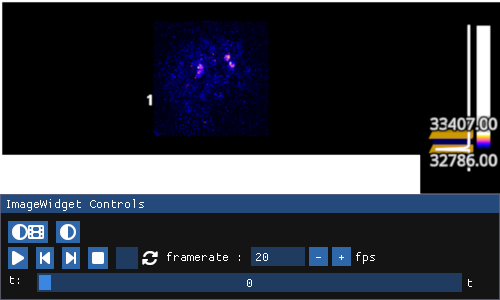

In [8]:
iw_movie = fpl.ImageWidget(movie, cmap="gnuplot2")
iw_movie.show()

RFBOutputContext()

JupyterWgpuCanvas()
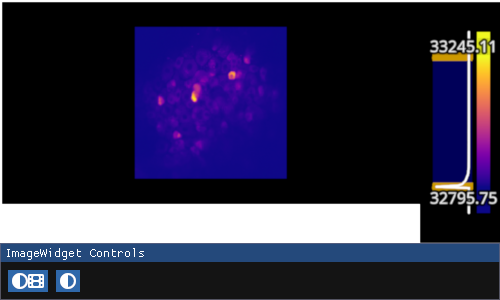

In [9]:
iw_mean = fpl.ImageWidget(movie_mean)
iw_mean.show()

In [10]:
movie = movie - movie_mean

In [11]:
series = movie.reshape(movie.shape[0], movie.shape[1] * movie.shape[2]).T

In [12]:
stsvd = SpaceTimeSVD(series, w=10)

In [ ]:
stsvd.compute(k=1)

Computing F, P


100%|██████████████████████████████████████████████████████████████████████████████████| 21609/21609 [00:00<00:00, 24895.85it/s]


(21609, 1360)
(108045, 1350)


100%|██████████████████████████████████████████████████████████████████████████████████| 21609/21609 [00:00<00:00, 56227.73it/s]


computing H


RFBOutputContext()

JupyterWgpuCanvas()
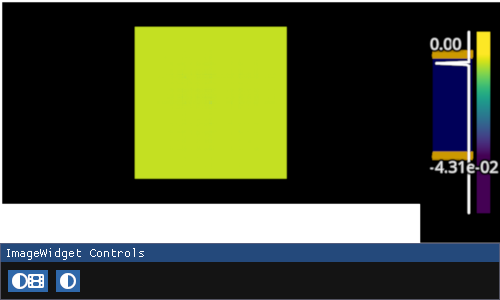

In [13]:
iw_a = fpl.ImageWidget(stsvd.adjacency, cmap="viridis")
iw_a.show()

In [14]:
from scipy.sparse.linalg import svds, eigsh
from itertools import product
import numpy as np
from scipy.linalg import qr, svd, hankel
from scipy.sparse.linalg import svds, eigsh
from tqdm import tqdm

In [15]:
class ClusteringCPQR:
    def __init__(self, adjacency: np.ndarray, max_k: int):
        self.max_k = max_k
        self.k = max_k
        self.B = np.abs(adjacency + adjacency.T) / 2
        self.evals, self.evecs = eigsh(self.B, k=self.max_k)

        if self.evals[-1] > self.evals[0]:
            # reverse order
            self.evecs = self.evecs[:, ::-1]

        self.Qk = self.evecs[:, :self.max_k]

        self.Qk.T[:] /= np.linalg.norm(self.Qk.T, axis=0, ord=2)

        _, _, self.pivots = qr(self.Qk.T, pivoting=True)

        self.P = self.Qk.T[:, self.pivots[:self.max_k]]
        u, s, vT = np.linalg.svd(self.P, full_matrices=False)
        self.W = u @ vT

        self.transformed = self.W.T @ self.Qk.T

        self.labels = self.transformed.argmax(axis=0)

    def update_k(self, k: int):
        self.k = k

        self.P = self.Qk.T[:, self.pivots[:self.k]]
        u, s, vT = np.linalg.svd(self.P, full_matrices=False)
        self.W = u @ vT

        self.transformed = self.W.T @ self.Qk.T

        self.labels = self.transformed.argmax(axis=0)

In [32]:
clustering = ClusteringCPQR(stsvd.adjacency, max_k=150)

In [17]:
from ipywidgets import IntSlider

In [18]:
fig = fpl.Figure()

RFBOutputContext()

In [33]:
from math import ceil

In [34]:
labels = clustering.labels.reshape(movie.shape[1], movie.shape[2])

In [35]:
cluster = 0

for i in range(10):
    for j in range(ceil(clustering.max_k / 10)):
        img = np.zeros((movie.shape[1], movie.shape[2]))
        
        img[labels == cluster] = 1
        fig[0, 0].add_image(img, offset=(i + (i * movie.shape[1]), j + (j * movie.shape[2]), 0))

        cluster += 1

JupyterWgpuCanvas(frame_feedback={'index': 2036, 'timestamp': 1725915871.6063437, 'localtime': 1725915871.633}…
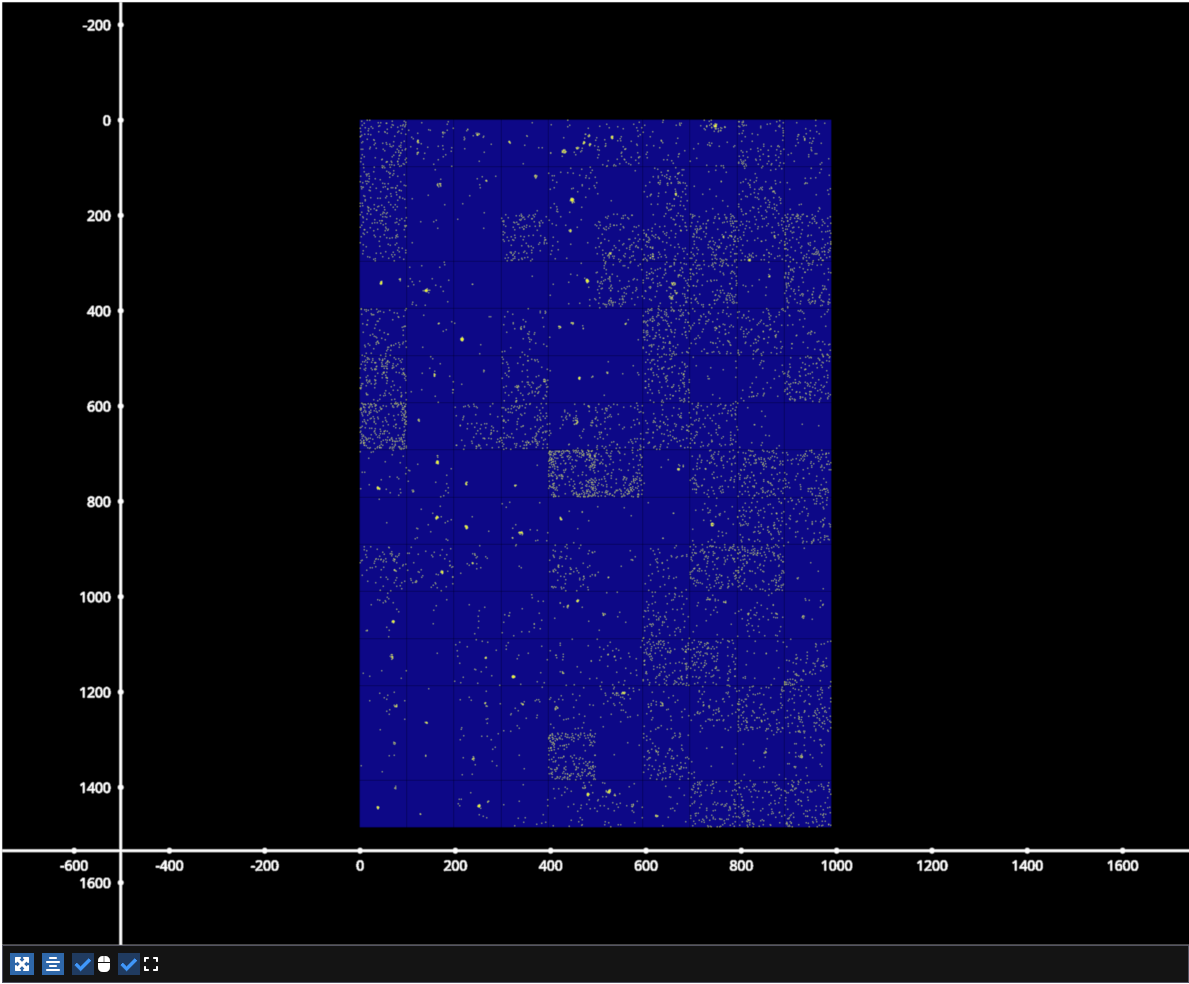

In [36]:
fig.show()

In [37]:
slider_k = IntSlider(min=1, max=clustering.max_k, step=1, value=clustering.max_k, description="k: ")

def update_k(change):
    fig.clear()
    k = change["new"]

    clustering.update_k(k)
    labels = clustering.labels.reshape(movie.shape[1], movie.shape[2])

    cluster = 0
    for i in range(10):
        for j in range(ceil(k / 10)):
            img = np.zeros((movie.shape[1], movie.shape[2]))
            
            img[labels == cluster] = 1
            fig[0, 0].add_image(img, offset=(i + (i * movie.shape[1]), j + (j * movie.shape[2]), 0))
    
            cluster += 1

    fig[0, 0].auto_scale()

slider_k.observe(update_k, "value")

slider_k

IntSlider(value=150, description='k: ', max=150, min=1)

In [50]:
iw.cmap = "viridis"

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas()
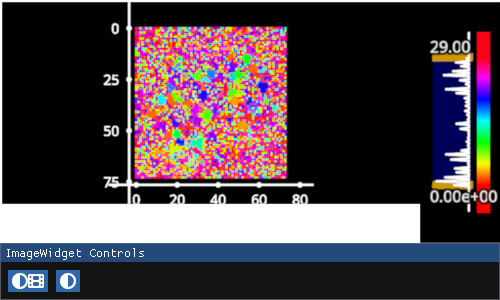

In [35]:
iw = fpl.ImageWidget(clustering.labels.reshape(movie.shape[1],  movie.shape[2]), cmap="hsv")
iw.show()